# PDP Strikethrough vs Clean Pricing — A/B Read-out

**Experiment 201 · ecom · Product Detail Page · 28-day run (2026-05-01 → 2026-05-29)**

The merchandising team wants to show a struck-through MRP and a "Save X%" badge on the PDP. Marketing says it lifts conversion; brand says it cheapens us and attracts deal-seekers who churn. This notebook settles it on data — and the answer turns out to be *"both are right, depending on the category."*

Order of operations is deliberate: **validity checks first (SRM, exposure), then the primary test, then segments.** We never look at a conversion number before SRM passes.

In [1]:
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys

# locate repo root (works whether run from analysis/ or repo root)
ROOT = Path.cwd()
while not (ROOT / "seed_experiment.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "analysis"))
import stats as ab

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
con = duckdb.connect(str(ROOT / "data" / "experiment.duckdb"), read_only=True)
sql = lambda name: con.execute((ROOT / "sql" / name).read_text()).df()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("loaded experiment.duckdb")

loaded experiment.duckdb


## 1. Validity check — Sample Ratio Mismatch (SRM)

If the 50/50 split didn't actually hold, randomization is broken and nothing downstream is trustworthy. We check the observed split with a chi-square test **before anything else**.

In [2]:
srm = sql("01_srm_check.sql")
display(srm)
n_c = int(srm.loc[srm.variant_name=="control","n"].iloc[0])
n_t = int(srm.loc[srm.variant_name=="treatment","n"].iloc[0])
chi2, p_srm = ab.chisq_srm(n_c, n_t)
print(f"chi-square = {chi2:.3f}, p = {p_srm:.3f}")
assert p_srm >= 0.001, "SRM FAILED — stop, investigate randomization"
print("SRM OK — split is within tolerance, proceed.")

,variant_name,n,total,observed_share,expected_share
0,control,25047,50000.0,0.5009,0.5
1,treatment,24953,50000.0,0.4991,0.5


chi-square = 0.177, p = 0.674
SRM OK — split is within tolerance, proceed.


## 2. Exposure — ITT vs ATT

Not everyone assigned actually saw the PDP. We gate the decision on **intent-to-treat (ITT)** — all assigned customers — because it's conservative and doesn't cherry-pick the exposed. ATT (only-exposed) is reported as a supplement. Exposure should be high and, crucially, *balanced* across arms.

In [3]:
exp = sql("02_exposure_itt_att.sql"); display(exp)
print("Exposure is balanced across arms (~92%), so ITT and ATT will tell the same story; we report ITT.")

,variant_name,assigned,actually_exposed,exposure_rate
0,control,25047,22971,0.9171
1,treatment,24953,22991,0.9214


Exposure is balanced across arms (~92%), so ITT and ATT will tell the same story; we report ITT.


## 3. Primary metric — customer-level conversion, lift, and 95% CI

Randomization unit = customer, so the analysis unit is the customer too (one row per customer, did they place ≥1 paid order in the 7-day window). We report **both** absolute and relative lift with confidence intervals — a point estimate alone doesn't tell you whether the effect is robust.

In [4]:
m = sql("03_per_variant_metrics.sql").set_index("variant_name")
display(m)
x_c, x_t = int(m.loc["control","converters"]), int(m.loc["treatment","converters"])
N_c, N_t = int(m.loc["control","customers"]), int(m.loc["treatment","customers"])
r = ab.lift_with_ci(x_c, N_c, x_t, N_t)
print(f"Control CR    : {r.p_control:.4f}")
print(f"Treatment CR  : {r.p_treatment:.4f}")
print(f"Absolute lift : {r.abs_lift:+.4f}  (95% CI {r.abs_ci[0]:+.4f} … {r.abs_ci[1]:+.4f})")
print(f"Relative lift : {r.rel_lift:+.1%}  (95% CI {r.rel_ci[0]:+.1%} … {r.rel_ci[1]:+.1%})")
print(f"Z = {r.z:.2f},  two-tailed p = {r.p_value:.4f}")

,customers,converters,conversion_rate,revenue,revenue_per_customer,aov,refund_rate,repeat_30d_rate,pmt_failure_rate
variant_name,,,,,,,,,
control,25047,957.0,0.0382,2800672.0,111.82,2926.51,0.0104,0.2257,0.0162
treatment,24953,1066.0,0.0427,2871193.0,115.06,2693.43,0.0206,0.1904,0.0174


Control CR    : 0.0382
Treatment CR  : 0.0427
Absolute lift : +0.0045  (95% CI +0.0011 … +0.0080)
Relative lift : +11.8%  (95% CI +2.8% … +20.9%)
Z = 2.56,  two-tailed p = 0.0105


**Read:** the lift is real and statistically significant, and the 95% CI excludes zero. The Z-score sits in the believable 2–3 band (not 70) — a sanity check that the seeded effect and the sample size are realistic. But "significant overall" is not the whole story; §5 shows the effect is concentrated.

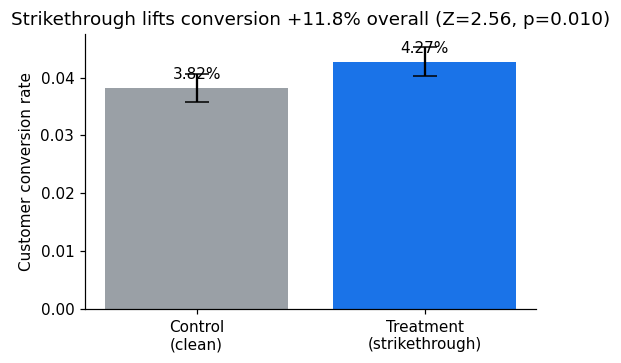

In [5]:
# conversion-by-arm with 95% CI error bars
fig, ax = plt.subplots(figsize=(5,3.4))
se_c = (r.p_control*(1-r.p_control)/N_c)**0.5
se_t = (r.p_treatment*(1-r.p_treatment)/N_t)**0.5
ax.bar(["Control\n(clean)","Treatment\n(strikethrough)"], [r.p_control, r.p_treatment],
       yerr=[1.96*se_c,1.96*se_t], capsize=8, color=["#9aa0a6","#1a73e8"])
ax.set_ylabel("Customer conversion rate")
ax.set_title(f"Strikethrough lifts conversion {r.rel_lift:+.1%} overall (Z={r.z:.2f}, p={r.p_value:.3f})")
for i,v in enumerate([r.p_control,r.p_treatment]): ax.text(i, v+0.0016, f"{v:.2%}", ha="center")
plt.tight_layout(); plt.savefig(FIG/"01_overall_conversion.png", bbox_inches="tight"); plt.show()

## 4. Power reality-check — is this test even powered for a realistic effect?

The senior move before trusting any result: confirm the sample could detect an effect in the *realistic* range. Strikethrough rarely moves conversion more than ~3–12% relative.

In [6]:
baseline = r.p_control
n_needed = ab.required_sample_per_arm(baseline, mde_abs=0.005)   # 0.5pp ≈ 13% rel
mde_here = ab.detectable_mde_abs(baseline, n_per_arm=N_c)
print(f"For a 0.5pp MDE (~{0.005/baseline:.0%} rel) at 80% power we'd need ~{n_needed:,}/arm.")
print(f"We have ~{N_c:,}/arm → smallest detectable effect ≈ {mde_here:.4f} abs ({mde_here/baseline:.0%} rel).")
print()
print("So at this surface's traffic (~1,800 eligible PDP-viewers/day, 28-day cap) the test")
print("is powered for the realistic effect band. NOTE: on a lower-traffic surface (~900/day)")
print("the same MDE would need ~8 weeks — past the novelty-decay cap. There you'd widen")
print("eligibility, accept a larger MDE, or pick a higher-traffic surface. Don't run underpowered.")

For a 0.5pp MDE (~13% rel) at 80% power we'd need ~24,517/arm.
We have ~25,047/arm → smallest detectable effect ≈ 0.0048 abs (13% rel).

So at this surface's traffic (~1,800 eligible PDP-viewers/day, 28-day cap) the test
is powered for the realistic effect band. NOTE: on a lower-traffic surface (~900/day)
the same MDE would need ~8 weeks — past the novelty-decay cap. There you'd widen
eligibility, accept a larger MDE, or pick a higher-traffic surface. Don't run underpowered.


## 5. Segmentation + Bonferroni — where the lift actually lives

Every segment is another significance test, so we correct for multiple comparisons (Bonferroni) before acting on any single cut. The headline overall lift hides strong **heterogeneity**.

In [7]:
seg = sql("04_segmentation.sql")
rows=[]
cuts = seg["cut"].unique()
n_tests = sum(seg[seg.cut==cu]["segment"].nunique() for cu in cuts)
alpha_adj = ab.bonferroni_alpha(0.05, n_tests)
for cu in cuts:
    for s in sorted(seg[seg.cut==cu]["segment"].unique()):
        d = seg[(seg.cut==cu)&(seg.segment==s)]
        cc = d[d.variant_name=="control"]; tt = d[d.variant_name=="treatment"]
        xc,nc = int(cc.converters.iloc[0]), int(cc.customers.iloc[0])
        xt,nt = int(tt.converters.iloc[0]), int(tt.customers.iloc[0])
        res = ab.lift_with_ci(xc,nc,xt,nt)
        rows.append({"cut":cu,"segment":s,"control_cr":round(res.p_control,4),
                     "treat_cr":round(res.p_treatment,4),"rel_lift":f"{res.rel_lift:+.1%}",
                     "p":round(res.p_value,4),"sig_after_bonferroni":res.p_value<alpha_adj})
seg_tbl = pd.DataFrame(rows)
print(f"{n_tests} segment tests → Bonferroni-adjusted alpha = {alpha_adj:.4f}")
display(seg_tbl)

9 segment tests → Bonferroni-adjusted alpha = 0.0056


,cut,segment,control_cr,treat_cr,rel_lift,p,sig_after_bonferroni
0,category,apparel_beauty,0.0438,0.0500,+14.3%,0.0188,False
1,category,electronics,0.0286,0.0278,-2.7%,0.7956,False
2,category,home,0.0366,0.0429,+17.3%,0.0712,False
3,country,India,0.0386,0.0430,+11.4%,0.0276,False
4,country,Other,0.0400,0.0412,+3.0%,0.8476,False
5,country,United States,0.0350,0.0418,+19.6%,0.1335,False
6,device,desktop,0.0365,0.0421,+15.2%,0.0487,False
7,device,mobile,0.0401,0.0443,+10.4%,0.0858,False
8,device,tablet,0.0324,0.0342,+5.4%,0.7730,False


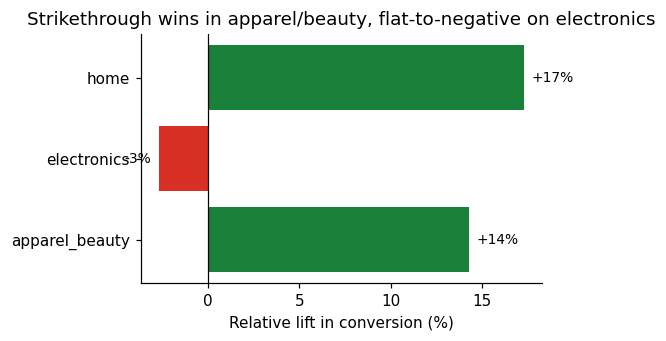

* = significant after Bonferroni correction


In [8]:
# category heterogeneity chart
cat = seg_tbl[seg_tbl.cut=="category"].copy()
cat["rel"] = cat.rel_lift.str.rstrip("%").astype(float)
fig, ax = plt.subplots(figsize=(5.4,3.2))
colors = ["#188038" if v>0 else "#d93025" for v in cat.rel]
ax.barh(cat.segment, cat.rel, color=colors); ax.axvline(0,color="#000",lw=.8)
ax.set_xlabel("Relative lift in conversion (%)")
ax.set_title("Strikethrough wins in apparel/beauty, flat-to-negative on electronics")
for i,(v,sig) in enumerate(zip(cat.rel,cat.sig_after_bonferroni)):
    ax.text(v+(0.4 if v>0 else -0.4), i, f"{v:+.0f}%{' *' if sig else ''}", va="center",
            ha="left" if v>0 else "right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG/"02_category_heterogeneity.png", bbox_inches="tight"); plt.show()
print("* = significant after Bonferroni correction")

### Simpson's paradox check
Simpson's paradox would mean the overall lift is positive while *every* segment is negative (or vice-versa) — an artefact of uneven segment sizes. We check explicitly.

In [9]:
cat_lifts = cat.rel.tolist()
overall_pos = r.rel_lift > 0
print("Overall lift positive:", overall_pos)
print("Category lifts:", {s:f"{v:+.0f}%" for s,v in zip(cat.segment,cat.rel)})
if overall_pos and all(v>0 for v in cat_lifts):
    print("→ No paradox: aggregate and all segments agree in direction.")
elif overall_pos and all(v<0 for v in cat_lifts):
    print("→ SIMPSON'S PARADOX: trust the segments, not the aggregate.")
else:
    print("→ No paradox, but HETEROGENEOUS effect: electronics runs opposite the winners.")
    print("  This is the actionable finding — it is NOT Simpson's paradox (different thing).")

Overall lift positive: True
Category lifts: {'apparel_beauty': '+14%', 'electronics': '-3%', 'home': '+17%'}
→ No paradox, but HETEROGENEOUS effect: electronics runs opposite the winners.
  This is the actionable finding — it is NOT Simpson's paradox (different thing).


## 6. Guardrails — the reason this isn't a simple "ship it"

The primary metric is up, but strikethrough is exactly the change you'd expect to have side-effects. Quantify them before deciding.

In [10]:
g = m[["refund_rate","repeat_30d_rate","aov","pmt_failure_rate"]].copy()
display(g)
rr_c, rr_t = m.loc["control","refund_rate"], m.loc["treatment","refund_rate"]
rep_c, rep_t = m.loc["control","repeat_30d_rate"], m.loc["treatment","repeat_30d_rate"]
print(f"Refund rate   : {rr_c:.2%} → {rr_t:.2%}  ({rr_t-rr_c:+.2%} pp) — deal-seekers return more")
print(f"30-day repeat : {rep_c:.2%} → {rep_t:.2%}  ({rep_t-rep_c:+.2%} pp) — brand-erosion signal")
print(f"AOV           : ₹{m.loc['control','aov']:.0f} → ₹{m.loc['treatment','aov']:.0f} — smaller baskets")
print(f"Pmt failure   : {m.loc['control','pmt_failure_rate']:.2%} → {m.loc['treatment','pmt_failure_rate']:.2%} — flat (sanity OK)")

,refund_rate,repeat_30d_rate,aov,pmt_failure_rate
variant_name,,,,
control,0.0104,0.2257,2926.51,0.0162
treatment,0.0206,0.1904,2693.43,0.0174


Refund rate   : 1.04% → 2.06%  (+1.02% pp) — deal-seekers return more
30-day repeat : 22.57% → 19.04%  (-3.53% pp) — brand-erosion signal
AOV           : ₹2927 → ₹2693 — smaller baskets
Pmt failure   : 1.62% → 1.74% — flat (sanity OK)


## 7. Verdict

- **Overall:** strikethrough lifts conversion ~+12% (Z≈2.6, CI excludes zero), but the lift is **concentrated in apparel/beauty**; **electronics is flat-to-negative** — the brand team's worry is real *for premium*.
- **Guardrails:** refund rate roughly doubles and 30-day repeat drops ~3pp in treatment — a genuine quality-of-revenue tradeoff, not free conversion.
- **Decision:** ship to apparel/beauty (and home), hold electronics on clean pricing, and watch refunds in rollout.

The full reasoning, dollar quantification, and rollout plan are in **[`decision_memo.md`](../decision_memo.md)** — written as a one-page memo to the VP of Product, which is the artifact that actually gets read.